# Stock Trend Predictor — Explainable Walkthrough

This notebook explains the complete process used by `app.py`. It downloads market data, creates technical indicators, visualizes the data, trains an XGBoost classifier and a LightGBM regressor, evaluates the models, and produces an example next-trading-day prediction.

The notebook is educational. A model prediction is an estimate and is not financial advice.

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, mean_absolute_error,
                             mean_squared_error)
import lightgbm as lgb
import xgboost as xgb
import yfinance as yf

plt.style.use('seaborn-v0_8-whitegrid')
pd.set_option('display.max_columns', 50)
RANDOM_STATE = 42
TICKER = 'TSLA'
print(f'Notebook configured for {TICKER}')

Notebook configured for TSLA


### Explanation

This cell imports the libraries used throughout the workflow. `yfinance` supplies historical market data, pandas manages tabular data, matplotlib creates graphs, XGBoost predicts direction, and LightGBM predicts the size of the next return. A fixed random seed makes model results more reproducible.

In [2]:
raw = yf.download(TICKER, period='10y', auto_adjust=False, progress=False)

# Current yfinance versions may return multi-level columns even for one ticker.
if isinstance(raw.columns, pd.MultiIndex):
    raw.columns = raw.columns.get_level_values(0)

raw = raw.sort_index()
print(f'Rows: {len(raw):,}')
print(f'Date range: {raw.index.min().date()} to {raw.index.max().date()}')
display(raw.head())
display(raw.describe().T.round(2))

Rows: 2,513
Date range: 2016-10-31 to 2026-10-29


c:\Users\shrey\Desktop\Major Project\venv\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
c:\Users\shrey\Desktop\Major Project\venv\Lib\site-packages\yfinance\utils.py:604: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  splits.set_index("date", inplace=True)
c:\Users\shrey\Desktop\Major Project\venv\Lib\site-packages\yfinance\utils.py:606: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  splits.so

Price,Adj Close,Close,High,Low,Open,Volume
Date,,,,,,
2016-10-31,13.182000,13.182000,13.499333,13.054000,13.499333,70384500
2016-11-01,12.719333,12.719333,13.233333,12.540667,13.202667,105900000
2016-11-02,12.534667,12.534667,12.846667,12.500667,12.670000,63801000
2016-11-03,12.494667,12.494667,12.764667,12.469333,12.600000,39795000
2016-11-04,12.704000,12.704000,12.897333,12.397333,12.600000,77190000


,count,mean,std,min,25%,50%,75%,max
Price,,,,,,,,
Adj Close,2513.0,1.807000e+02,139.52,11.93,22.77,196.37,2.831500e+02,4.898800e+02
Close,2513.0,1.807000e+02,139.52,11.93,22.77,196.37,2.831500e+02,4.898800e+02
High,2513.0,1.845600e+02,142.39,12.32,23.16,199.68,2.882600e+02,4.988300e+02
Low,2513.0,1.766800e+02,136.61,11.80,22.37,191.36,2.763100e+02,4.853300e+02
Open,2513.0,1.807200e+02,139.60,12.07,22.79,196.10,2.830800e+02,4.898800e+02
Volume,2513.0,1.140407e+08,73097446.88,16500234.00,69298400.00,95438100.00,1.313250e+08,9.140820e+08


### Explanation

The model uses roughly ten years of daily OHLCV data. The `Close` column is the main price series, while `Volume` describes trading activity. The column-normalization step prevents later calculations from failing when Yahoo Finance returns a multi-index table.

In [12]:
def engineer_features(df):
    df = df.copy()
    if isinstance(df.columns, pd.MultiIndex):
        df.columns = df.columns.get_level_values(0)

    # Returns, lagged returns, trend, and volatility
    df['Return'] = df['Close'].pct_change()
    df['Lag_1'] = df['Return'].shift(1)
    df['Lag_2'] = df['Return'].shift(2)
    df['SMA_10'] = df['Close'].rolling(10).mean() / df['Close'] - 1
    df['SMA_50'] = df['Close'].rolling(50).mean() / df['Close'] - 1
    df['Volatility'] = df['Return'].rolling(10).std()

    # Relative Strength Index (RSI)
    delta = df['Close'].diff()
    gain = delta.where(delta > 0, 0).rolling(14).mean()
    loss = (-delta.where(delta < 0, 0)).rolling(14).mean()
    df['RSI'] = 100 - (100 / (1 + gain / loss))

    # Moving Average Convergence Divergence (MACD)
    exp12 = df['Close'].ewm(span=12, adjust=False).mean()
    exp26 = df['Close'].ewm(span=26, adjust=False).mean()
    df['MACD'] = exp12 - exp26
    df['MACD_Signal'] = df['MACD'].ewm(span=9, adjust=False).mean()
    df['MACD_Hist'] = df['MACD'] - df['MACD_Signal']

    # Bollinger Bands
    mean20 = df['Close'].rolling(20).mean()
    std20 = df['Close'].rolling(20).std()
    df['BB_Upper'] = mean20 + 2 * std20
    df['BB_Lower'] = mean20 - 2 * std20
    df['BB_Position'] = (df['Close'] - df['BB_Lower']) / (df['BB_Upper'] - df['BB_Lower'])
    df['BB_Width'] = (df['BB_Upper'] - df['BB_Lower']) / mean20
    return df

data = engineer_features(raw)
feature_columns = ['Lag_1', 'Lag_2', 'SMA_10', 'SMA_50', 'Volatility', 'Volume',
                   'RSI', 'MACD', 'MACD_Signal', 'MACD_Hist', 'BB_Position', 'BB_Width']
display(data[feature_columns].tail().round(4))

Price,Lag_1,Lag_2,SMA_10,SMA_50,Volatility,Volume,RSI,MACD,MACD_Signal,MACD_Hist,BB_Position,BB_Width
Date,,,,,,,,,,,,
2026-10-23,-0.0308,0.0341,-0.0026,-0.0227,0.0236,34763000,46.3554,2.6359,2.7659,-0.1300,0.5562,0.1131
2026-10-26,-0.0063,-0.0308,-0.0485,-0.0686,0.0289,53090200,55.1236,3.9816,3.0091,0.9726,0.9517,0.1194
2026-10-27,0.0521,-0.0063,-0.0776,-0.1015,0.0307,45333200,62.3820,6.2542,3.6581,2.5961,1.1462,0.1371
2026-10-28,0.0404,0.0521,-0.0610,-0.0909,0.0295,35450700,62.1588,7.7050,4.4675,3.2375,1.0041,0.1445
2026-10-29,-0.0080,0.0404,-0.0535,-0.0913,0.0285,16500234,60.0474,8.8615,5.3463,3.5152,0.9696,0.1472


### Explanation

Feature engineering converts raw prices into signals that a machine-learning model can use. Lagged returns describe recent momentum, moving averages describe trend relative to the current price, volatility measures recent variability, RSI describes buying/selling momentum, MACD describes trend momentum, and Bollinger features describe the current price position inside a volatility band. Rolling indicators intentionally create missing values at the beginning of the dataset.

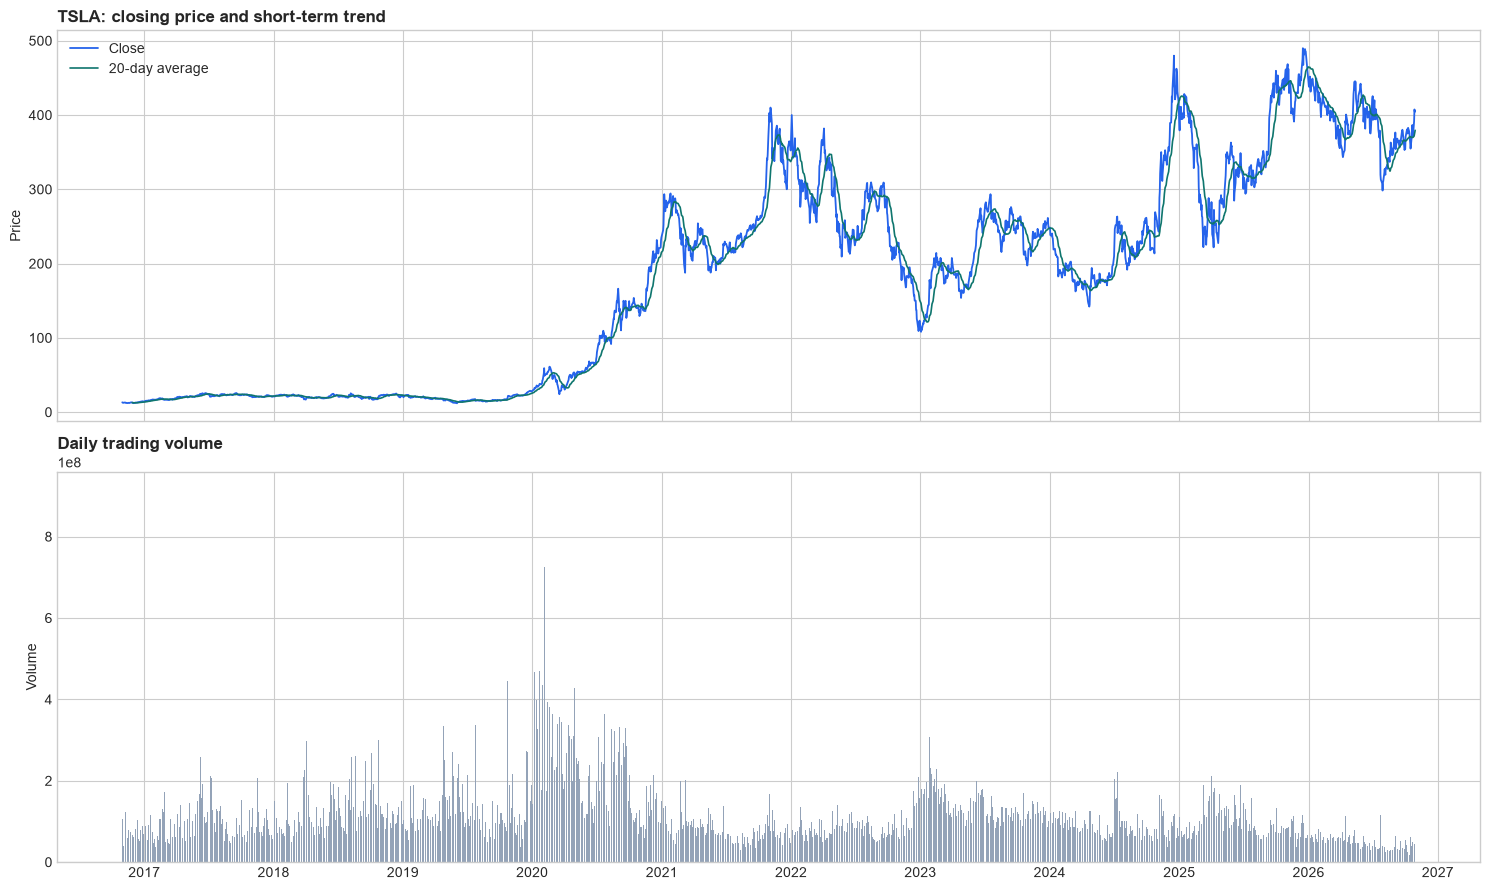

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(15, 9), sharex=True)
axes[0].plot(data.index, data['Close'], color='#2563EB', linewidth=1.3, label='Close')
axes[0].plot(data.index, data['Close'].rolling(20).mean(), color='#0F766E', linewidth=1.2, label='20-day average')
axes[0].set_title(f'{TICKER}: closing price and short-term trend', loc='left', fontweight='bold')
axes[0].set_ylabel('Price')
axes[0].legend()
axes[1].bar(data.index, data['Volume'], color='#94A3B8', width=1.0)
axes[1].set_title('Daily trading volume', loc='left', fontweight='bold')
axes[1].set_ylabel('Volume')
plt.tight_layout()
plt.show()

### Explanation

This graph gives the first visual inspection of the dataset. The top panel shows price and a 20-day average; the lower panel shows volume. Large volume bars can coincide with important price movements, but the model is not told to interpret the graph directly—it receives the numerical features created above.

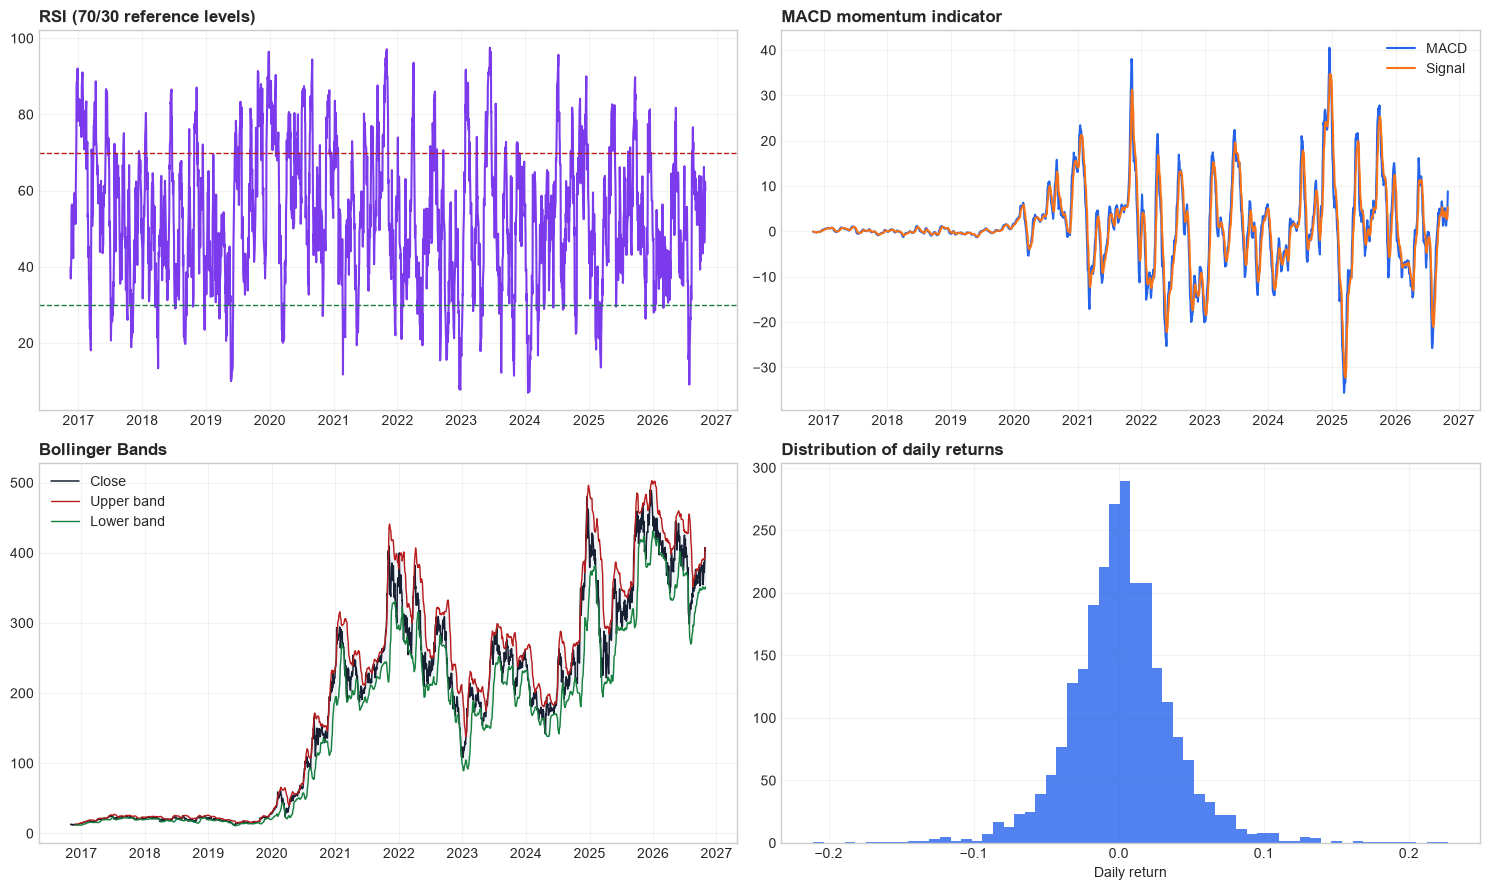

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
axes[0, 0].plot(data.index, data['RSI'], color='#7C3AED')
axes[0, 0].axhline(70, color='#B91C1C', linestyle='--', linewidth=1)
axes[0, 0].axhline(30, color='#15803D', linestyle='--', linewidth=1)
axes[0, 0].set_title('RSI (70/30 reference levels)', loc='left', fontweight='bold')
axes[0, 1].plot(data.index, data['MACD'], label='MACD', color='#2563EB')
axes[0, 1].plot(data.index, data['MACD_Signal'], label='Signal', color='#F97316')
axes[0, 1].set_title('MACD momentum indicator', loc='left', fontweight='bold')
axes[0, 1].legend()
axes[1, 0].plot(data.index, data['Close'], color='#172033', linewidth=1.1, label='Close')
axes[1, 0].plot(data.index, data['BB_Upper'], color='#B91C1C', linewidth=1, label='Upper band')
axes[1, 0].plot(data.index, data['BB_Lower'], color='#15803D', linewidth=1, label='Lower band')
axes[1, 0].fill_between(data.index, data['BB_Lower'], data['BB_Upper'], color='#CBD5E1', alpha=.25)
axes[1, 0].set_title('Bollinger Bands', loc='left', fontweight='bold')
axes[1, 0].legend()
axes[1, 1].hist(data['Return'].dropna(), bins=60, color='#2563EB', alpha=.8)
axes[1, 1].set_title('Distribution of daily returns', loc='left', fontweight='bold')
axes[1, 1].set_xlabel('Daily return')
for ax in axes.flat:
    ax.grid(alpha=.25)
plt.tight_layout()
plt.show()

### Explanation

These four diagnostic plots make the engineered indicators interpretable. RSI values near the upper or lower reference levels can indicate strong recent momentum. MACD and its signal line show whether short-term momentum is above or below its smoothed reference. Bollinger Bands show changing volatility, and the return histogram shows how daily changes are distributed.

In [6]:
model_data = data.copy()
# Classification target: will tomorrow's close be higher than today's close?
model_data['Target_Class'] = (model_data['Close'].shift(-1) > model_data['Close']).astype(int)
# Regression target: tomorrow's percentage return
model_data['Target_Reg'] = model_data['Close'].pct_change().shift(-1)

model_data = model_data.dropna(subset=feature_columns + ['Target_Class', 'Target_Reg'])
X = model_data[feature_columns]
y_class = model_data['Target_Class']
y_reg = model_data['Target_Reg']

# Time order matters for financial data: do not randomly shuffle the past and future.
split = int(len(model_data) * 0.80)
X_train, X_test = X.iloc[:split], X.iloc[split:]
y_class_train, y_class_test = y_class.iloc[:split], y_class.iloc[split:]
y_reg_train, y_reg_test = y_reg.iloc[:split], y_reg.iloc[split:]
print(f'Training rows: {len(X_train):,} | Test rows: {len(X_test):,}')
print(f'Up days in all usable data: {y_class.mean():.1%}')

Training rows: 1,970 | Test rows: 493
Up days in all usable data: 51.8%


### Explanation

The notebook creates two targets. `Target_Class` is a binary label for direction, while `Target_Reg` is a continuous next-day return. The final 20% of observations are held out as a test period. A chronological split is important because training on future observations would create look-ahead bias.

In [7]:
classifier = xgb.XGBClassifier(
    n_estimators=100, max_depth=3, learning_rate=0.01,
    subsample=0.8, random_state=RANDOM_STATE, n_jobs=-1
)
classifier.fit(X_train, y_class_train)

regressor = lgb.LGBMRegressor(
    n_estimators=60, max_depth=3, num_leaves=21, learning_rate=0.02,
    random_state=RANDOM_STATE, verbose=-1, n_jobs=-1
)
regressor.fit(X_train, y_reg_train)
print('Both models trained successfully.')

Both models trained successfully.


### Explanation

Two specialized models are trained. XGBoost is used as a classifier because the direction target has two classes. LightGBM is used as a regressor because the return target is numeric. The hyperparameters mirror the application and intentionally keep the models compact enough for an interactive desktop tool.

In [8]:
class_predictions = classifier.predict(X_test)
reg_predictions = regressor.predict(X_test)

accuracy = accuracy_score(y_class_test, class_predictions)
mae = mean_absolute_error(y_reg_test, reg_predictions)
rmse = np.sqrt(mean_squared_error(y_reg_test, reg_predictions))
print(f'Direction accuracy: {accuracy:.2%}')
print(f'Return MAE: {mae:.6f} ({mae:.4%})')
print(f'Return RMSE: {rmse:.6f} ({rmse:.4%})')
print('\nClassification report:')
print(classification_report(y_class_test, class_predictions,
                            target_names=['Down', 'Up'], zero_division=0))
print('Confusion matrix [actual rows x predicted columns]:')
display(pd.DataFrame(confusion_matrix(y_class_test, class_predictions),
                     index=['Actual Down', 'Actual Up'],
                     columns=['Predicted Down', 'Predicted Up']))

Direction accuracy: 51.93%
Return MAE: 0.026434 (2.6434%)
Return RMSE: 0.035351 (3.5351%)

Classification report:
              precision    recall  f1-score   support

        Down       0.53      0.27      0.35       244
          Up       0.52      0.77      0.62       249

    accuracy                           0.52       493
   macro avg       0.52      0.52      0.49       493
weighted avg       0.52      0.52      0.49       493

Confusion matrix [actual rows x predicted columns]:


,Predicted Down,Predicted Up
Actual Down,65,179
Actual Up,58,191


### Explanation

Accuracy measures how often the direction was correct on the unseen test period. MAE and RMSE measure the distance between predicted and actual returns; smaller values are better. The confusion matrix separates correct up/down predictions from errors, which is more informative than a single accuracy number.

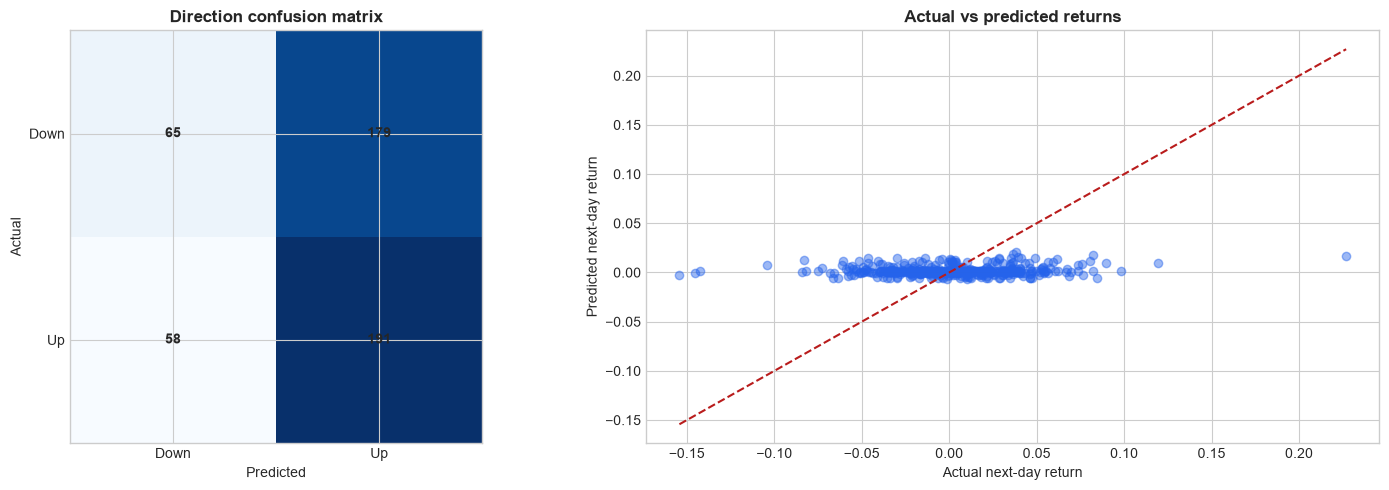

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

cm = confusion_matrix(y_class_test, class_predictions)
axes[0].imshow(cm, cmap='Blues')
axes[0].set_title('Direction confusion matrix', fontweight='bold')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')
axes[0].set_xticks([0, 1], ['Down', 'Up'])
axes[0].set_yticks([0, 1], ['Down', 'Up'])
for row in range(2):
    for col in range(2):
        axes[0].text(col, row, cm[row, col], ha='center', va='center', fontweight='bold')

axes[1].scatter(y_reg_test, reg_predictions, alpha=.45, color='#2563EB')
min_value = min(y_reg_test.min(), reg_predictions.min())
max_value = max(y_reg_test.max(), reg_predictions.max())
axes[1].plot([min_value, max_value], [min_value, max_value], '--', color='#B91C1C')
axes[1].set_title('Actual vs predicted returns', fontweight='bold')
axes[1].set_xlabel('Actual next-day return')
axes[1].set_ylabel('Predicted next-day return')
plt.tight_layout()
plt.show()

### Explanation

The left chart visualizes classification errors: darker or larger counts show where the model makes more decisions. The right chart compares actual and predicted returns. Points close to the diagonal represent accurate magnitude estimates; wide scatter indicates that return prediction is difficult for that period.

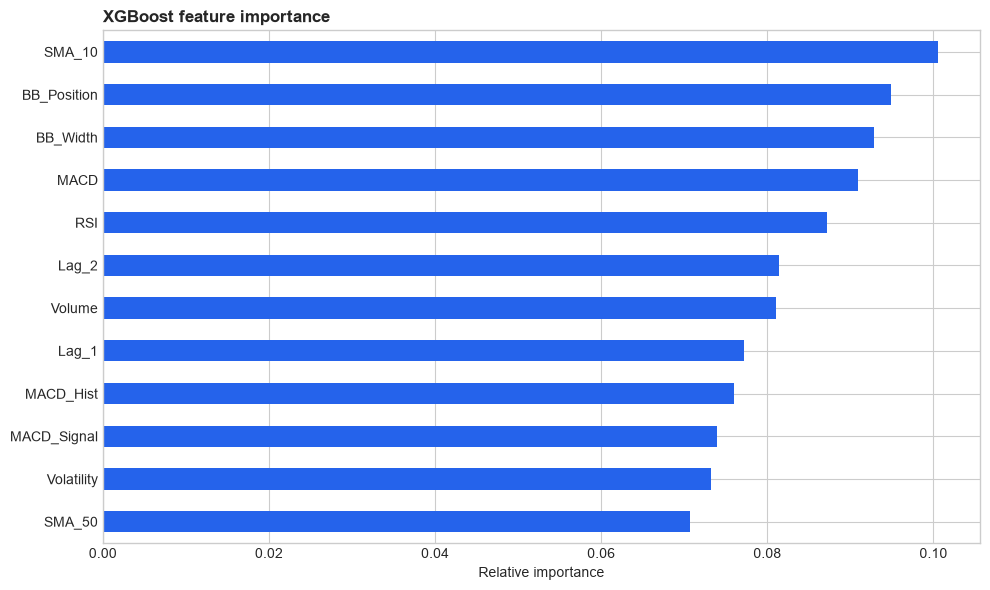

,importance
SMA_10,0.1006
BB_Position,0.0949
BB_Width,0.0929
MACD,0.0910
RSI,0.0872
Lag_2,0.0814
Volume,0.0811
Lag_1,0.0772
MACD_Hist,0.0760
MACD_Signal,0.0739


In [10]:
importance = pd.Series(classifier.feature_importances_, index=feature_columns)
importance = importance.sort_values(ascending=True)
plt.figure(figsize=(10, 6))
importance.plot.barh(color='#2563EB')
plt.title('XGBoost feature importance', loc='left', fontweight='bold')
plt.xlabel('Relative importance')
plt.tight_layout()
plt.show()
display(importance.sort_values(ascending=False).to_frame('importance').round(4))

### Explanation

Feature importance provides a basic explanation of which inputs the XGBoost model used most often when splitting the data. It is not proof of causation and it does not mean that a feature independently causes price movement. It is best interpreted together with domain knowledge and out-of-sample validation.

Ticker: TSLA
Latest close: $405.57
Predicted direction: UP
Direction confidence: 60.17%
Expected next-day return: +0.93%
Illustrative predicted price: $409.32


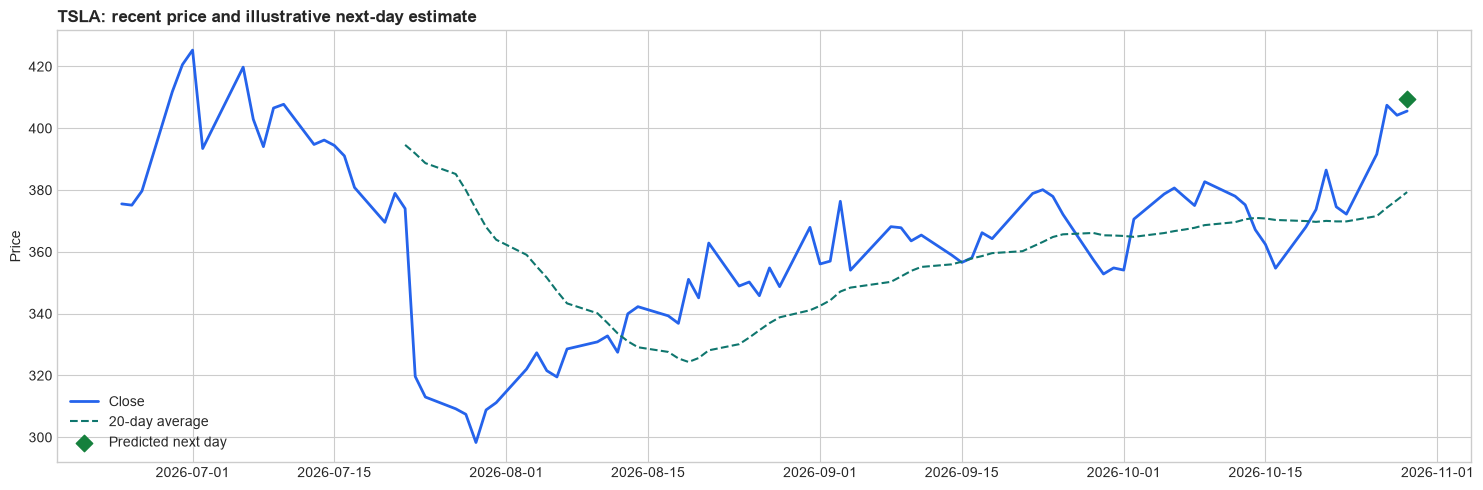

In [11]:
# Build the same latest-row prediction used by the desktop app.
latest_row = data.dropna(subset=feature_columns).iloc[[-1]][feature_columns]
direction = int(classifier.predict(latest_row)[0])
probabilities = classifier.predict_proba(latest_row)[0]
expected_return = float(regressor.predict(latest_row)[0])
latest_close = float(data['Close'].iloc[-1])
predicted_price = latest_close * (1 + expected_return)

print(f'Ticker: {TICKER}')
print(f'Latest close: ${latest_close:,.2f}')
print(f'Predicted direction: {"UP" if direction else "DOWN"}')
print(f'Direction confidence: {probabilities[direction]:.2%}')
print(f'Expected next-day return: {expected_return:+.2%}')
print(f'Illustrative predicted price: ${predicted_price:,.2f}')

recent = data.tail(90)
plt.figure(figsize=(15, 5))
plt.plot(recent.index, recent['Close'], color='#2563EB', linewidth=2, label='Close')
plt.plot(recent.index, recent['Close'].rolling(20).mean(), color='#0F766E',
         linestyle='--', label='20-day average')
plt.scatter([recent.index[-1]], [predicted_price], color='#15803D', marker='D',
            s=70, label='Predicted next day', zorder=5)
plt.title(f'{TICKER}: recent price and illustrative next-day estimate', loc='left', fontweight='bold')
plt.ylabel('Price')
plt.legend()
plt.tight_layout()
plt.show()

### Explanation

This final cell reproduces the app's inference step. The classifier returns a direction and class probabilities, while the regressor returns an expected percentage move. Multiplying the latest close by one plus the expected return gives an illustrative price estimate for the chart. The estimate should be treated as an uncertain model output, not as a guaranteed future price.

## Summary

The pipeline is: download data → engineer indicators → create future targets → split chronologically → train two models → evaluate on unseen data → inspect feature importance → generate a current estimate. The most important safeguards are avoiding future data leakage, checking the test-period metrics, and remembering that historical patterns do not guarantee future market behavior.